# Where do sound and listening agree? Canonical correlation between audio embeddings and listening embeddings (RQ4)

## Background and question
This project studies the Yambda dataset (Yandex Music listening logs) and asks whether recommendations broaden or narrow what people listen to.
Yambda is anonymous: tracks have no titles and **no genre labels**. What a track *sounds like* is known only through a **128-dimensional audio embedding** per track.
To talk about "genres" we cluster the audio embeddings with spherical k-means and call each cluster a **pseudo-genre**.

**Research question 4:** are these pseudo-genres *real structure*, or an *artefact of the clustering*?
Clustering the audio can only show structure *in sound*. A stronger test uses a second, independent source: **how people actually listen**. If two tracks are played in the same sessions, that is a behavioural statement about them that does not depend on their audio.

This notebook compares two representations of the same tracks:
- a **sound representation**: the audio embedding;
- a **listening representation**: a vector per track learned from listening sessions (*item2vec*: tracks played near each other get similar vectors; the same idea as word embeddings, with tracks as words and sessions as sentences).

It uses **canonical correlation analysis (CCA)**, which separates *what sound and listening share* from what each contains alone, and asks:
1. How much of the listening structure can be predicted from sound, and in how many independent directions?
2. Is this just **artist** memorisation? (Tested by predicting listening for **artists the model has never seen**.)
3. Do the shared directions line up with the pseudo-genres, or with popularity?
4. Are the pseudo-genres **cohesive in listening space**, also when pairs of tracks by the same artist or on the same album are excluded, and for several numbers of pseudo-genres k?
5. (Extension) Is the relation between sound and listening the same for tracks chosen by users (organic) and tracks chosen by the recommender?

## Plan: what each step is for
| # | Step | What we want to learn |
|---|---|---|
| 1 | Listening embeddings from sessions | a vector per track that describes who it is played with, built without using audio |
| 2 | Aligning sound and listening | the tracks that have both, and a check of whether the listening vectors mostly encode popularity |
| 3 | Canonical correlation | how much sound and listening share, with a chance level, with unseen tracks and with unseen artists; sensitivity checks |
| 4 | What the shared directions are | whether they follow the pseudo-genres or popularity |
| 5 | Pseudo-genres in listening space | cohesion (with artist and album controls) and agreement between listening clusters and pseudo-genres, for k = 8, 16, 32, 64 |
| 6 | Extension: organic versus recommended listening | whether the sound-listening relation differs by who chose the track |
| 7 | Evidence ledger, summary and limitations | what all analyses of the pseudo-genres say together |

*Prerequisites:* the processed embeddings `data/processed/emb50m_*.npy` (created by `scripts/extract_embeddings_50m.py`), the raw Yambda-50M events and the artist and album mappings in `data/raw/yambda/`.
Run time: roughly 20 minutes. Memory: below 3 GB. The notebook also saves the listening embeddings to `data/processed/` for later use.

## 0. Setup and parameters

In [1]:
from pathlib import Path
import time
import zlib
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from scipy.sparse import csr_matrix
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from gensim.models import Word2Vec

# ---------------- parameters (change here, then Run All) ----------------
REAL_PCT = 50            # a real listen = at least this % of the track played
SESSION_GAP_S = 30 * 60  # a gap longer than this between two listens starts a new session
SESSION_CAP = 50         # at most this many distinct tracks per session are used
VEC = 64                 # dimensions of the listening embedding
WINDOW, NEG, EPOCHS, MIN_COUNT = 5, 10, 5, 20   # item2vec settings (context window, negative samples, passes, minimum plays)
W2V_WORKERS = 8
N_REMOVE_PC = 0          # leading directions removed from the listening embedding (checked in section 2.1 and 3.3)
CCA_REG = 1e-2           # ridge regularisation of the covariance matrices in CCA
TEST_FRAC = 0.2
K_GRID = [8, 16, 32, 64] # numbers of pseudo-genres
K_MAIN = 32
N_FIT = 150_000          # tracks used to fit the pseudo-genre k-means
N_SEEDS = 3
SEED = 42

rng = np.random.default_rng(SEED)
logging.getLogger("gensim").setLevel(logging.ERROR)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COL = {"organic": "#2a9d8f", "recommended": "#e76f51"}
REAL, NULL, ACC = "#264653", "#9aa0a6", "#e76f51"

ROOT = Path.cwd()
while not (ROOT / "data" / "raw" / "yambda").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Could not find data/raw/yambda above " + str(Path.cwd()))
    ROOT = ROOT.parent
DATA, PROC = ROOT / "data" / "raw" / "yambda", ROOT / "data" / "processed"
print("project root:", ROOT)

project root: C:\MSc DTU\Semester 3\01. CTDS\Music


## 1. Listening embeddings from sessions (item2vec)

### 1.1 Design choices, and why
**Sessions as sentences.** A *session* is a run of listens by one user without a pause of more than 30 minutes. Tracks played in the same session are treated as co-occurring, like words in a sentence. Within a session we keep each track once, in order of first play, and at most 50 tracks, so that a long loop of one album does not dominate.

**Why item2vec (skip-gram with negative sampling).** It learns a vector per track such that tracks that appear in the same sessions get similar vectors, using only listening behaviour and no audio. It is the standard way to turn co-occurrence into an embedding;
it is cheap, needs no labels and gives vectors that can be compared directly with the audio embeddings.

**Why two streams.** Every listen in Yambda is flagged *organic* (the user chose it) or *recommended* (the recommender chose it). We train one listening embedding on each stream. Sections 3 to 5 describe the organic stream (the users' own choices);
section 6 compares the two.

**Fair comparison between streams.** Both streams are cut to the **same number of tokens** (track plays inside sessions; sessions are drawn at random until the budget is reached), because the amount of training data drives the quality of an embedding.
The recommended stream has longer sessions, so equal tokens means fewer sessions there.

**Reproducibility.** Training with several threads is not bit-for-bit reproducible even with a seed; section 3.4 therefore re-trains with another seed and checks that the conclusions do not move.

In [2]:
def rank_in_sorted_groups(g):
    start = np.r_[0, np.flatnonzero(g[1:] != g[:-1]) + 1]
    return np.arange(len(g)) - np.repeat(start, np.diff(np.r_[start, len(g)]))

def load_sessions(organic):
    flt = [("event_type", "=", "listen"), ("played_ratio_pct", ">=", REAL_PCT), ("is_organic", "=", 1 if organic else 0)]
    tbl = pq.read_table(DATA / "flat/50m/multi_event.parquet", columns=["uid", "item_id", "timestamp"], filters=flt)
    uid = tbl["uid"].to_numpy().astype(np.int64); item = tbl["item_id"].to_numpy().astype(np.int64); ts = tbl["timestamp"].to_numpy().astype(np.int64)
    del tbl
    order = np.lexsort((ts, uid)); uid, item, ts = uid[order], item[order], ts[order]; del order
    new_sess = np.r_[True, uid[1:] != uid[:-1]] | np.r_[True, (ts[1:] - ts[:-1]) > SESSION_GAP_S]
    sid = np.cumsum(new_sess) - 1
    n_listens, n_users = len(item), len(np.unique(uid))
    _, first = np.unique(sid * (item.max() + 1) + item, return_index=True); first.sort()   # each track once per session, in order of first play
    sid, item = sid[first], item[first]
    keep = rank_in_sorted_groups(sid) < SESSION_CAP
    sid, item = sid[keep], item[keep]
    us, inv, cnt = np.unique(sid, return_inverse=True, return_counts=True)
    ok = (cnt >= 2)[inv]                                                                   # sessions with at least 2 tracks
    return item[ok].astype(np.int64), np.unique(inv[ok], return_inverse=True)[1], n_listens, n_users

t0 = time.time()
streams = {}
for name, org in [("organic", True), ("recommended", False)]:
    tok, sess, nl, nu = load_sessions(org)
    streams[name] = dict(tok=tok, sess=sess, listens=nl, users=nu)
    print(f"{name}: {nl:,} real listens of {nu:,} users -> {sess.max() + 1:,} sessions, {len(tok):,} tokens ({time.time() - t0:.0f} s)")
budget = min(len(s["tok"]) for s in streams.values())
for name, s in streams.items():
    n_s = s["sess"].max() + 1
    lens = np.bincount(s["sess"], minlength=n_s)
    shuffled = rng.permutation(n_s)
    chosen = np.sort(shuffled[np.cumsum(lens[shuffled]) <= budget])
    m = np.isin(s["sess"], chosen)
    s["tok"], s["sess"] = s["tok"][m], np.unique(s["sess"][m], return_inverse=True)[1]
    s["starts"] = np.r_[0, np.flatnonzero(s["sess"][1:] != s["sess"][:-1]) + 1, len(s["tok"])]
    print(f"{name}: cut to {s['sess'].max() + 1:,} sessions, {len(s['tok']):,} tokens ({len(s['tok']) / (s['sess'].max() + 1):.1f} tracks per session)")

organic: 14,121,730 real listens of 8,798 users -> 1,174,731 sessions, 11,700,950 tokens (6 s)


recommended: 15,317,548 real listens of 8,592 users -> 1,020,522 sessions, 13,045,615 tokens (13 s)


organic: cut to 1,174,731 sessions, 11,700,950 tokens (10.0 tracks per session)


recommended: cut to 915,304 sessions, 11,700,931 tokens (12.8 tracks per session)


In [3]:
class Corpus:
    # yields one session at a time as a list of track-id strings (keeps memory low)
    def __init__(self, tok, starts): self.tok, self.starts = tok, starts
    def __iter__(self):
        for a, b in zip(self.starts[:-1], self.starts[1:]): yield [str(x) for x in self.tok[a:b]]

def det_hash(s): return zlib.crc32(s.encode())     # makes the random initialisation independent of the Python process

def train_w2v(name, seed):
    s = streams[name]
    return Word2Vec(Corpus(s["tok"], s["starts"]), vector_size=VEC, window=WINDOW, sg=1, negative=NEG, min_count=MIN_COUNT, sample=1e-4,
                    epochs=EPOCHS, workers=W2V_WORKERS, seed=seed, hashfxn=det_hash)

def to_arrays(m):
    keys = m.wv.index_to_key
    return np.array([int(k) for k in keys]), np.asarray(m.wv.vectors, dtype=np.float64), np.array([m.wv.get_vecattr(k, "count") for k in keys])

t0 = time.time(); w2v = {}
for name in streams:
    w2v[name] = to_arrays(train_w2v(name, SEED)); print(f"{name}: item2vec trained, {len(w2v[name][0]):,} tracks with at least {MIN_COUNT} plays ({time.time() - t0:.0f} s)")

organic: item2vec trained, 77,703 tracks with at least 20 plays (108 s)


recommended: item2vec trained, 73,010 tracks with at least 20 plays (224 s)


## 2. Aligning sound and listening

**Which tracks.** Only tracks that have *both* an audio embedding and a listening embedding **in both streams** can be compared, so that the organic and recommended analyses use exactly the same tracks.
Tracks need at least 20 plays per stream, so rarely played tracks (whose listening vectors would be noise) are excluded; as a consequence the results describe well-known tracks, not the long tail.

**Artist and album labels.** Needed only for controls: they let us test on artists the model has not seen (section 3) and exclude same-artist and same-album pairs (section 5).

**Does the listening embedding mostly encode popularity?** Embeddings of this kind sometimes have a leading direction that reflects how often an item occurs rather than what it occurs with. If that were the case here, the comparison with sound would partly measure popularity, and a standard remedy is to remove it
("all but the top", Mu and Viswanath, 2018). **We check instead of assuming:** we measure the share of variance in the leading direction and its correlation with log popularity (number of organic plays), and decide on that basis whether to remove it (`N_REMOVE_PC`). Section 3.3 repeats the analysis with 0, 1 and 3 directions removed and with popularity regressed out.

In [4]:
emb_ids = np.load(PROC / "emb50m_item_ids.npy")
EN = np.load(PROC / "emb50m_norm.npy")
L = int(max(emb_ids.max(), *(w2v[n][0].max() for n in w2v))) + 1
item_row = np.full(L, -1, dtype=np.int64); item_row[emb_ids] = np.arange(len(emb_ids))

common = np.intersect1d(w2v["organic"][0], w2v["recommended"][0]); common = common[item_row[common] >= 0]
pos = {n: pd.Index(w2v[n][0]).get_indexer(common) for n in w2v}
Xa = EN[item_row[common]].astype(np.float64)                     # audio embeddings of the common tracks (unit length)
pop = np.log1p(w2v["organic"][2][pos["organic"]])                # log number of organic plays: a popularity measure
print(f"{len(common):,} tracks have an audio embedding and a listening embedding in both streams")

def first_map(path, col):
    mp = pd.read_parquet(path).drop_duplicates("item_id").set_index("item_id")[col]
    return mp.reindex(common).fillna(-1).astype(np.int64).to_numpy()
art_c = first_map(DATA / "artist_item_mapping.parquet", "artist_id")
alb_c = first_map(DATA / "album_item_mapping.parquet", "album_id")
print(f"artist known for {(art_c >= 0).mean():.1%} and album known for {(alb_c >= 0).mean():.1%} of these tracks; {len(np.unique(art_c[art_c >= 0])):,} distinct artists")

def unit(Z): return Z / np.maximum(np.linalg.norm(Z, axis=1, keepdims=True), 1e-12)
def postprocess(V, n_remove):
    V = V - V.mean(0)
    if n_remove:
        _, _, Vt = np.linalg.svd(V, full_matrices=False); T = Vt[:n_remove]; V = V - (V @ T.T) @ T
    return unit(V)

Vo = w2v["organic"][1][pos["organic"]]; Vc = Vo - Vo.mean(0); _, S_, Vt_ = np.linalg.svd(Vc, full_matrices=False)
r_pc = [np.corrcoef(Vc @ Vt_[j], pop)[0, 1] for j in range(10)]
print(f"leading direction of the organic listening embedding: {S_[0] ** 2 / (S_ ** 2).sum():.1%} of the variance; correlation of its score with log-popularity {r_pc[0]:+.2f}")
print(f"largest absolute correlation with log-popularity among the first 10 directions: {np.max(np.abs(r_pc)):.2f}")
Y = {n: postprocess(w2v[n][1][pos[n]], N_REMOVE_PC) for n in w2v}   # listening embeddings used below

# save the listening embeddings (raw item2vec vectors, before any post-processing) for later use
PROC.mkdir(exist_ok=True)
np.save(PROC / "listening_emb_item_ids.npy", common)
for n in w2v: np.save(PROC / f"listening_emb_{n}_raw.npy", w2v[n][1][pos[n]].astype(np.float32))
print(f"saved listening_emb_item_ids.npy and listening_emb_{{organic,recommended}}_raw.npy to {PROC}")

# two ways of splitting the tracks into fitting and held-out tracks
n_te = int(TEST_FRAC * len(common)); perm = rng.permutation(len(common))
split_random = (perm[n_te:], perm[:n_te])                                  # held-out tracks, but artists are shared with the fitting tracks
groups = np.where(art_c >= 0, art_c, -1 - np.arange(len(common)))          # tracks without artist information form groups of their own
tr_g, te_g = next(GroupShuffleSplit(1, test_size=TEST_FRAC, random_state=SEED).split(Xa, groups=groups))
split_artist = (tr_g, te_g)                                                # held-out artists: no artist occurs on both sides
assert not (set(art_c[te_g][art_c[te_g] >= 0]) & set(art_c[tr_g][art_c[tr_g] >= 0]))
splits = {"random tracks": split_random, "unseen artists": split_artist}
print({k_: f"{len(v[0]):,} fit / {len(v[1]):,} held out" for k_, v in splits.items()})

49,112 tracks have an audio embedding and a listening embedding in both streams


artist known for 100.0% and album known for 100.0% of these tracks; 11,349 distinct artists


leading direction of the organic listening embedding: 10.8% of the variance; correlation of its score with log-popularity +0.10
largest absolute correlation with log-popularity among the first 10 directions: 0.21
saved listening_emb_item_ids.npy and listening_emb_{organic,recommended}_raw.npy to C:\MSc DTU\Semester 3\01. CTDS\Music\data\processed
{'random tracks': '39,290 fit / 9,822 held out', 'unseen artists': '38,631 fit / 10,481 held out'}


### 2.1 Reading the alignment

**The tracks.** 49,112 tracks have both an audio embedding and a listening embedding in both streams (each stream was trained on 11.7 million tokens; the recommended stream has longer sessions, 12.8 against 10.0 tracks, hence fewer sessions: 915,304 against 1,174,731). They belong to 11,349 distinct artists, and artist and album are known for all of them.

**The listening embedding does not mostly encode popularity.** Its leading direction carries 10.8% of the variance, but its correlation with log popularity is only +0.10, and among the first 10 directions the largest absolute correlation is 0.21. We therefore **keep all directions** (`N_REMOVE_PC = 0`); section 3.3 confirms that popularity explains very little of the relation to sound.

**The two splits.** The random split holds out 9,822 tracks; the artist split holds out 10,481 tracks of artists that never occur among the 38,631 fitting tracks (checked by an assertion).

## 3. Canonical correlation: what do sound and listening share?

### 3.1 The method
CCA looks for a direction $a_1$ in audio space and a direction $b_1$ in listening space such that the two scores $x^\top a_1$ and $y^\top b_1$ are as correlated as possible across tracks. That correlation is the first *canonical correlation* $\rho_1$.
The next pair is the most correlated pair *uncorrelated with the first*, and so on, giving $\rho_1\ge\rho_2\ge\dots$ for as many pairs as the smaller representation has dimensions (64).
The number of large correlations tells **how many independent directions sound and listening share**; the squared correlations tell how much of the variation in these directions is shared.

**Regularisation.** A small ridge term (1% of the average variance) keeps the solution stable in directions with little variance.

**Two ways to hold out tracks.** CCA fitted and judged on the same tracks overstates the correlation, so every number is computed on tracks not used for fitting. We use two splits:
- **Random tracks** (20% of tracks held out): the usual check against overfitting. Tracks of the same artist may be on both sides, so a model could in principle exploit artist identity.
- **Unseen artists** (20% of *artists* held out; no artist appears on both sides): the stricter check. The model can only succeed by learning how sound relates to listening in general, not by recognising an artist.

**Null model.** To see what held-out correlation arises by chance, we fit CCA with the **pairing between sound and listening shuffled** on the fitting tracks and evaluate on the true pairs; anything above that level is real shared structure.

**A simpler second view.** A **ridge regression from audio to the listening vector** gives one number: the share of the variance of the listening embedding on held-out tracks that audio predicts ($R^2$; 0 = no better than predicting the average).

In [5]:
def inv_sqrt(Cm):
    w, Q = np.linalg.eigh(Cm); return (Q / np.sqrt(np.maximum(w, 1e-12))) @ Q.T

def cca_fit(X, Yv, reg=CCA_REG):
    mx, my = X.mean(0), Yv.mean(0); Xc, Yc = X - mx, Yv - my; n_ = len(X)
    Cxx, Cyy, Cxy = Xc.T @ Xc / n_, Yc.T @ Yc / n_, Xc.T @ Yc / n_
    Cxx = Cxx + reg * np.trace(Cxx) / len(Cxx) * np.eye(len(Cxx)); Cyy = Cyy + reg * np.trace(Cyy) / len(Cyy) * np.eye(len(Cyy))
    Wx, Wy = inv_sqrt(Cxx), inv_sqrt(Cyy)
    U, s, Vt = np.linalg.svd(Wx @ Cxy @ Wy, full_matrices=False)
    return dict(mx=mx, my=my, A=Wx @ U, B=Wy @ Vt.T, rho_train=s)

def cca_scores(m, X, Yv): return (X - m["mx"]) @ m["A"], (Yv - m["my"]) @ m["B"]
def cca_corr(m, X, Yv):
    a, b = cca_scores(m, X, Yv); a = a - a.mean(0); b = b - b.mean(0)
    return (a * b).sum(0) / np.sqrt((a ** 2).sum(0) * (b ** 2).sum(0))

def evaluate_cca(Yv, tr, te):
    m = cca_fit(Xa[tr], Yv[tr]); rho_te = cca_corr(m, Xa[te], Yv[te])
    m0 = cca_fit(Xa[tr], Yv[tr][rng.permutation(len(tr))]); rho_null = cca_corr(m0, Xa[te], Yv[te])      # pairing shuffled
    rr = RidgeCV(alphas=[0.01, 0.1, 1, 10, 100]).fit(Xa[tr], Yv[tr]); pred = rr.predict(Xa[te])
    sst = ((Yv[te] - Yv[tr].mean(0)) ** 2).sum(0); r2_dim = 1 - ((Yv[te] - pred) ** 2).sum(0) / sst; r2 = 1 - ((Yv[te] - pred) ** 2).sum() / sst.sum()
    return dict(model=m, rho_train=m["rho_train"], rho_test=rho_te, rho_null=rho_null, r2=r2, r2_dim=r2_dim, shared_var=float((rho_te ** 2).mean()))

cca_res = {(n, sp): evaluate_cca(Y[n], *splits[sp]) for n in Y for sp in splits}
rows = []
for sp in splits:
    r = cca_res[("organic", sp)]
    rows.append({"held-out": sp, "R^2 (audio -> listening)": r["r2"], "top canonical corr": r["rho_test"][0], "mean of top 5": r["rho_test"][:5].mean(), "mean of top 10": r["rho_test"][:10].mean(),
                 "mean squared (all 64)": r["shared_var"], "chance: largest |corr|": np.abs(r["rho_null"]).max()})
print("organic listening vs audio:"); print(pd.DataFrame(rows).set_index("held-out").T.to_string(float_format=lambda x: f"{x:.3f}"))
r = cca_res[("organic", "random tracks")]
print(f"\nrandom-track split: top 5 canonical correlations on held-out tracks {np.round(r['rho_test'][:5], 3)} (fitting tracks {np.round(r['rho_train'][:5], 3)})")

organic listening vs audio:
held-out                  random tracks  unseen artists
R^2 (audio -> listening)          0.441           0.437
top canonical corr                0.902           0.899
mean of top 5                     0.864           0.862
mean of top 10                    0.782           0.784
mean squared (all 64)             0.154           0.146
chance: largest |corr|            0.113           0.106

random-track split: top 5 canonical correlations on held-out tracks [0.902 0.891 0.873 0.833 0.823] (fitting tracks [0.9   0.893 0.874 0.835 0.824])


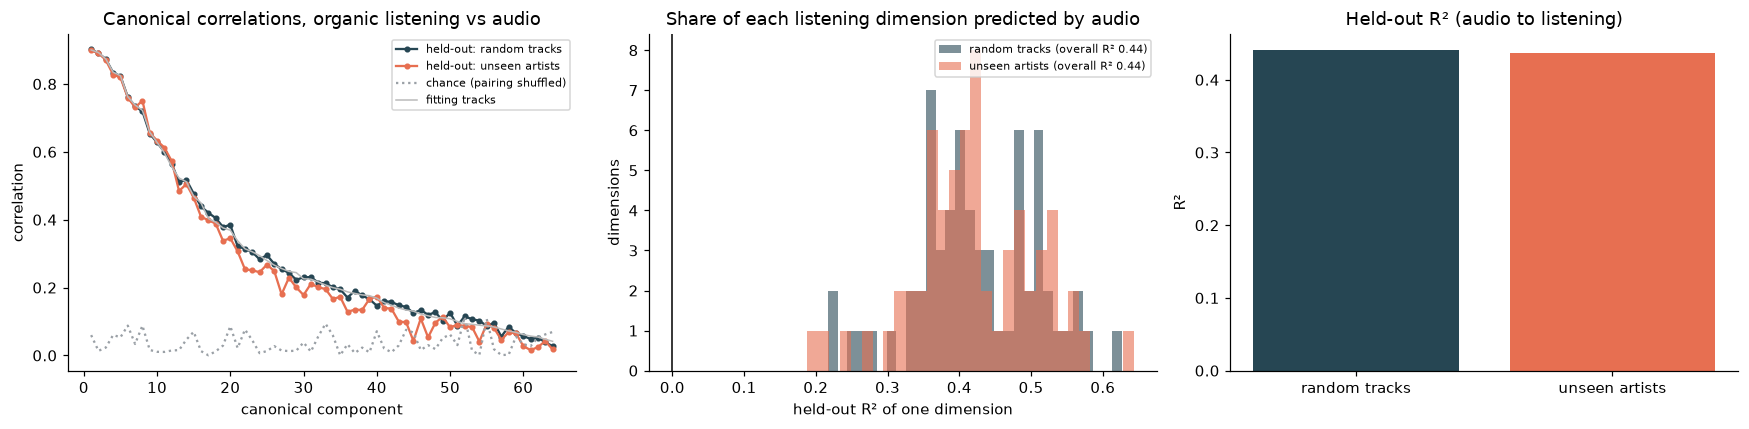

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
comp = np.arange(1, 65)
for sp, c in [("random tracks", REAL), ("unseen artists", ACC)]:
    ax[0].plot(comp, cca_res[("organic", sp)]["rho_test"], "o-", ms=3, color=c, label=f"held-out: {sp}")
ax[0].plot(comp, np.abs(cca_res[("organic", "random tracks")]["rho_null"]), ":", color=NULL, label="chance (pairing shuffled)")
ax[0].plot(comp, cca_res[("organic", "random tracks")]["rho_train"], "-", color="#bbbbbb", lw=1, label="fitting tracks")
ax[0].set(title="Canonical correlations, organic listening vs audio", xlabel="canonical component", ylabel="correlation"); ax[0].legend(fontsize=7)
for sp, c in [("random tracks", REAL), ("unseen artists", ACC)]:
    ax[1].hist(cca_res[("organic", sp)]["r2_dim"], bins=30, alpha=.6, color=c, label=f"{sp} (overall R² {cca_res[('organic', sp)]['r2']:.2f})")
ax[1].axvline(0, color="k", lw=1); ax[1].set(title="Share of each listening dimension predicted by audio", xlabel="held-out R² of one dimension", ylabel="dimensions"); ax[1].legend(fontsize=7)
ax[2].bar(["random tracks", "unseen artists"], [cca_res[("organic", s_)]["r2"] for s_ in splits], color=[REAL, ACC]); ax[2].set(title="Held-out R² (audio to listening)", ylabel="R²")
plt.tight_layout(); plt.show()

### 3.2 Reading the canonical correlations

**Sound and listening share a lot, in many independent directions.** On held-out tracks of the organic stream:
- The strongest canonical correlations are **0.90, 0.89, 0.87, 0.83, 0.82**, nearly identical on the fitting tracks (0.90, 0.89, 0.87, 0.84, 0.82), so this is not overfitting. The chance level (pairing shuffled) is at most 0.11. The mean of the 10 strongest is 0.78 and the mean squared canonical correlation over all 64 directions is 0.15.
- A ridge regression predicts **44% of the variance of the listening embedding from the audio alone** on unseen tracks ($R^2=0.44$).

**It is not artist memorisation.** On tracks of artists the model has never seen, the numbers are practically the same: $R^2=0.437$ against 0.441, top correlation 0.899 against 0.902, mean of the top 10 0.784 against 0.782. A model that relied on recognising artists would do much worse on unseen artists; instead, what sound tells about listening **generalises across artists**.

**It is not popularity** (section 3.3). Regressing popularity out (linear and quadratic in log plays) leaves $R^2$ at 0.434 for unseen artists (0.437 without). Removing leading directions of the listening embedding *lowers* $R^2$ (0.437, 0.389 and 0.287 with 0, 1 and 3 directions removed), which means that those directions contain sound-related structure; this is why we keep them.

**It is reproducible** (section 3.4): a second item2vec training with another seed gives the same $R^2$ (0.441 against 0.441 on random tracks, 0.438 against 0.437 on unseen artists) and the same leading correlations.

**Reading with care.** CCA and ridge regression are *linear* methods, so they can miss nonlinear dependence between sound and listening but cannot create it; the shared structure is a lower bound. The listening embedding itself depends on item2vec settings that were fixed in advance and not tuned.

### 3.3 Sensitivity: leading directions and popularity
**Why.** The listening embedding should reflect *what a track is played with*, not just how popular it is. Section 2 measured how strongly the leading direction relates to popularity; here we also test, directly, what happens to the shared structure if we
(a) remove 0, 1 or 3 leading directions, or (b) **regress popularity out** (linear and quadratic in log plays) from the listening vectors before comparing with sound.

**What we want to learn.** Whether the conclusion (a large, many-directional overlap between sound and listening) survives each treatment, or whether it was popularity in disguise.

In [7]:
def quick(Yv):
    out = {}
    for sp, (tr, te) in splits.items():
        rr = RidgeCV(alphas=[0.01, 0.1, 1, 10, 100]).fit(Xa[tr], Yv[tr]); pred = rr.predict(Xa[te])
        out[f"R^2 ({sp})"] = 1 - ((Yv[te] - pred) ** 2).sum() / ((Yv[te] - Yv[tr].mean(0)) ** 2).sum()
    tr, te = splits["unseen artists"]; m = cca_fit(Xa[tr], Yv[tr]); out["top canonical corr (unseen artists)"] = cca_corr(m, Xa[te], Yv[te])[0]
    return out

rows = []
for nr in [0, 1, 3]:
    rows.append({"treatment": f"{nr} leading direction(s) removed", **quick(postprocess(w2v["organic"][1][pos["organic"]], nr))})
D = np.c_[np.ones(len(pop)), pop, pop ** 2]; Vraw = w2v["organic"][1][pos["organic"]]
resid = Vraw - D @ np.linalg.lstsq(D, Vraw, rcond=None)[0]
rows.append({"treatment": "popularity regressed out (linear + quadratic)", **quick(unit(resid))})
sens = pd.DataFrame(rows).set_index("treatment"); print(sens.to_string(float_format=lambda x: f"{x:.3f}"))

                                               R^2 (random tracks)  R^2 (unseen artists)  top canonical corr (unseen artists)
treatment                                                                                                                    
0 leading direction(s) removed                               0.441                 0.437                                0.899
1 leading direction(s) removed                               0.393                 0.389                                0.890
3 leading direction(s) removed                               0.291                 0.287                                0.821
popularity regressed out (linear + quadratic)                0.438                 0.434                                0.893


### 3.4 Sensitivity to training luck
**Why.** item2vec training is random (and not bit-for-bit reproducible with several threads). **What we do.** We train the organic listening embedding a second time with another seed and recompute the key numbers on the same tracks and the same splits.
**What we want to learn.** Whether the numbers are properties of the data and not of one training run.

In [8]:
v2 = to_arrays(train_w2v("organic", SEED + 1))
pos2 = pd.Index(v2[0]).get_indexer(common); assert (pos2 >= 0).all()
Y2 = postprocess(v2[1][pos2], N_REMOVE_PC)
for sp in splits:
    a_, b_ = cca_res[("organic", sp)], evaluate_cca(Y2, *splits[sp])
    print(f"{sp}: first training R^2 {a_['r2']:.3f}, top 5 corr {np.round(a_['rho_test'][:5], 3)} | second training R^2 {b_['r2']:.3f}, top 5 corr {np.round(b_['rho_test'][:5], 3)}")

random tracks: first training R^2 0.441, top 5 corr [0.902 0.891 0.873 0.833 0.823] | second training R^2 0.441, top 5 corr [0.902 0.89  0.873 0.833 0.823]


unseen artists: first training R^2 0.437, top 5 corr [0.899 0.891 0.871 0.828 0.819] | second training R^2 0.438, top 5 corr [0.899 0.892 0.87  0.829 0.819]


## 4. What are the shared directions?

**Why.** A canonical correlation tells *how much* is shared, not *what*. Shared directions could follow the pseudo-genres, but could also follow something else that both sound and listening reflect, such as popularity.

**Pseudo-genres.** Spherical k-means on the audio embeddings (each scaled to unit length; every track goes to the centroid with the highest cosine similarity, centroids are re-normalised means, k-means++ seeding). The centroids are fitted on a random sample of 150,000 of the 848k embedded tracks and **all** tracks are assigned to the nearest centroid,
for k = 8, 16, 32, 64 with three random starts each; they are used again in section 5.

**What we do.** For the 10 strongest canonical components (held-out tracks, random split) we measure
- **η² by pseudo-genre** (k = 32): the share of the component's variance that lies *between* the pseudo-genres rather than within them (high means the shared direction is a pseudo-genre axis);
- the **correlation with popularity**.

**What we want to learn.** Whether what sound and listening agree on is mostly genre-like or mostly something else.

12 pseudo-genre clusterings (34 s)
 component   rho  eta2_sound  eta2_listening  corr_pop
         1 0.902       0.835           0.698    -0.132
         2 0.891       0.796           0.641    -0.113
         3 0.873       0.710           0.551     0.024
         4 0.833       0.549           0.394     0.048
         5 0.823       0.590           0.418    -0.108
         6 0.762       0.393           0.243    -0.062
         7 0.734       0.617           0.357    -0.081
         8 0.719       0.490           0.290     0.027
         9 0.654       0.360           0.175     0.006
        10 0.628       0.439           0.197    -0.053


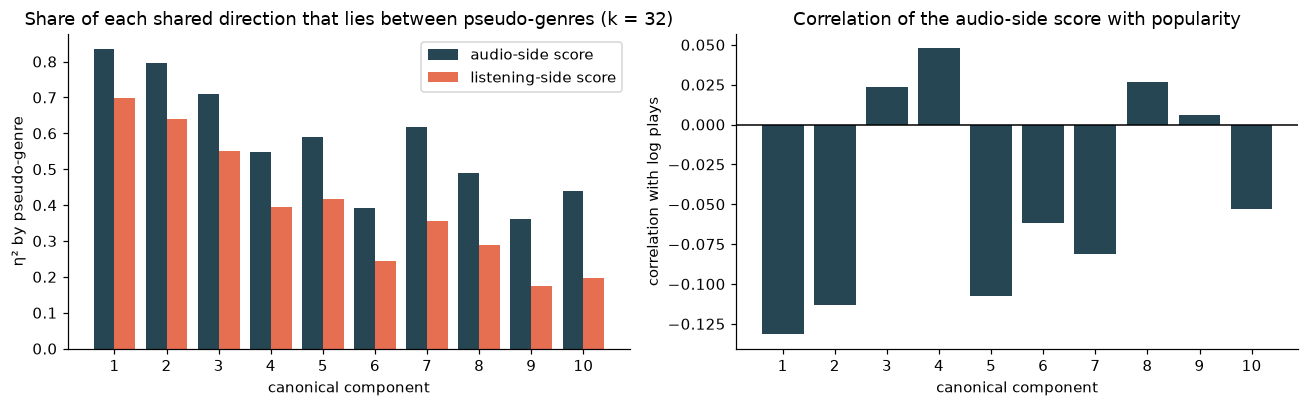

In [9]:
def spherical_kmeans(X, k, seed, n_iter=60):
    r_ = np.random.default_rng(seed); n_ = len(X)
    Cn = np.empty((k, X.shape[1]), dtype=np.float32); Cn[0] = X[r_.integers(n_)]
    dist = 1 - X @ Cn[0]
    for j in range(1, k):                                   # k-means++ seeding with cosine distance
        pr = np.maximum(dist, 0) ** 2; Cn[j] = X[r_.choice(n_, p=pr / pr.sum())]
        dist = np.minimum(dist, 1 - X @ Cn[j])
    labels = np.full(n_, -1)
    for _ in range(n_iter):
        new = np.argmax(X @ Cn.T, axis=1)
        if (new == labels).mean() > 0.9995:
            labels = new; break
        labels = new
        sums = csr_matrix((np.ones(n_, np.float32), (labels, np.arange(n_))), shape=(k, n_)) @ X
        nrm = np.linalg.norm(sums, axis=1, keepdims=True)
        empty = nrm[:, 0] == 0
        sums[empty] = X[r_.integers(n_, size=empty.sum())]; nrm[empty] = 1
        Cn = (sums / np.maximum(nrm, 1e-9)).astype(np.float32)
    return Cn, labels

t0 = time.time()
Xa32 = Xa.astype(np.float32)
fit_idx = rng.choice(len(EN), N_FIT, replace=False)
cent = {(k, s): spherical_kmeans(EN[fit_idx], k, SEED + 100 * s)[0] for k in K_GRID for s in range(N_SEEDS)}
pgc = {key: np.argmax(Xa32 @ Cn.T, axis=1) for key, Cn in cent.items()}          # pseudo-genres of the common tracks
print(f"{len(cent)} pseudo-genre clusterings ({time.time() - t0:.0f} s)")
pg = pgc[(K_MAIN, 0)]

def eta2(score, lab):
    mu = score.mean(); tot = ((score - mu) ** 2).sum()
    return sum(((lab == c).sum() * (score[lab == c].mean() - mu) ** 2) for c in np.unique(lab)) / tot

tr_r, te_r = splits["random tracks"]
a_te, b_te = cca_scores(cca_res[("organic", "random tracks")]["model"], Xa[te_r], Y["organic"][te_r])
NC = 10
comp_tab = pd.DataFrame([dict(component=j + 1, rho=cca_res[("organic", "random tracks")]["rho_test"][j], eta2_sound=eta2(a_te[:, j], pg[te_r]), eta2_listening=eta2(b_te[:, j], pg[te_r]),
                              corr_pop=np.corrcoef(a_te[:, j], pop[te_r])[0, 1]) for j in range(NC)])
print(comp_tab.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8)); w = 0.4
ax[0].bar(comp_tab.component - w / 2, comp_tab.eta2_sound, w, color=REAL, label="audio-side score"); ax[0].bar(comp_tab.component + w / 2, comp_tab.eta2_listening, w, color=ACC, label="listening-side score")
ax[0].set(title=f"Share of each shared direction that lies between pseudo-genres (k = {K_MAIN})", xlabel="canonical component", ylabel="η² by pseudo-genre"); ax[0].legend(); ax[0].set_xticks(comp_tab.component)
ax[1].bar(comp_tab.component, comp_tab.corr_pop, color=REAL); ax[1].axhline(0, color="k", lw=1); ax[1].set_xticks(comp_tab.component)
ax[1].set(title="Correlation of the audio-side score with popularity", xlabel="canonical component", ylabel="correlation with log plays")
plt.tight_layout(); plt.show()

### 4.1 Reading the shared directions

**The strongest shared directions are largely pseudo-genre axes.** For the first component, 84% of the variance of the audio-side score and 70% of the listening-side score lie *between* the 32 pseudo-genres; for components 2 and 3 the values are 80/64% and 71/55%.
Further down the share falls and varies (components 4 to 10: 55/39%, 59/42%, 39/24%, 62/36%, 49/29%, 36/18%, 44/20%): the weaker shared directions increasingly describe differences *within* pseudo-genres.
So the clearest thing sound and listening agree on is what separates the pseudo-genres.

**It is not popularity.** The correlation of every one of the 10 strongest audio-side scores with log popularity is small (at most 0.13 in absolute value).

**Caveat.** The pseudo-genres are built from the large audio axes, and the CCA directions are by construction the ones that listening can predict from audio, so some overlap is expected, and the audio-side η² is not corrected for it. The result says that *the main shared structure coincides with the pseudo-genre differences*;
it cannot by itself separate "genres" from "any large axis of the audio embedding". The cohesion analysis below is the more direct test.

## 5. The pseudo-genres in listening space

CCA is about linear directions. The question that matters for the pseudo-genres is simpler: **are the tracks of one pseudo-genre actually played together?** This section answers it for four numbers of pseudo-genres, with controls.

### 5.1 Cohesion of pseudo-genres in listening space
**What we do.** For each pseudo-genre we draw random pairs of its tracks and average the cosine similarity of their *listening* vectors; the **lift** is that average minus the same for random pairs of tracks from anywhere. A positive lift means tracks of one pseudo-genre are more alike in listening than tracks in general.
The lifts of the pseudo-genres are averaged weighted by their size. The null is the same calculation with **shuffled labels** (cluster sizes preserved), where the lift should be about 0.

**Controls.** Pairs of tracks by the same artist, or on the same album, sound alike and are played together, so they could produce a lift by themselves. We therefore repeat the calculation **excluding all same-artist pairs**, and **excluding all same-artist and same-album pairs**, both in the pseudo-genre pairs and in the baseline of random pairs.

**What we want to learn.** Whether pseudo-genres are cohesive in listening, for every k, also between *different* artists and albums.

### 5.2 Clustering the listening embedding itself
**What we do.** We cluster the *listening* vectors with the same spherical k-means and compare these listening clusters with the sound pseudo-genres (ARI, adjusted Rand index: agreement of two partitions corrected for chance, 0 = chance, 1 = identical; and NMI, normalised mutual information, which also suits partitions of different structure).
The fair yardstick is how much two runs of the *sound* clustering agree with each other (the ceiling). We also compute the **artist purity lift** (artists with at least 5 tracks: share of an artist's tracks in their most common cluster, minus the same with shuffled labels) for both kinds of clusters.
**What we want to learn.** Whether grouping tracks by listening gives the same partition as grouping by sound, and how strongly each follows artists.

cohesion lift of the pseudo-genres in organic listening space (mean over 3 k-means starts):
excluded  none  artist  artist or album
k                                      
8        0.193   0.192            0.193
16       0.246   0.245            0.244
32       0.287   0.285            0.287
64       0.323   0.319            0.320
with shuffled labels:
excluded   none  artist  artist or album
k                                       
8         0.001  -0.000            0.000
16       -0.000   0.000            0.000
32       -0.000  -0.000            0.000
64       -0.000   0.001            0.001



k = 32, same-artist and same-album pairs excluded: 32 of 32 pseudo-genres have a positive lift (lowest 0.170, median 0.306, highest 0.565)


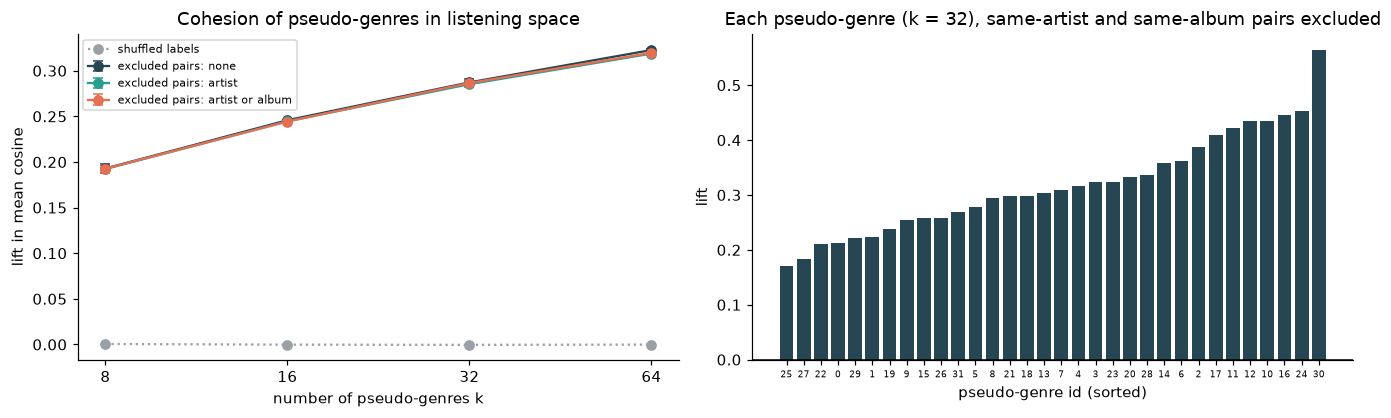

In [10]:
def pair_cos(Yu, a, b, exclude):
    ok = a != b
    if exclude in ("artist", "artist or album"): ok &= ~((art_c[a] == art_c[b]) & (art_c[a] >= 0))
    if exclude == "artist or album": ok &= ~((alb_c[a] == alb_c[b]) & (alb_c[a] >= 0))
    return np.einsum("ij,ij->i", Yu[a[ok]], Yu[b[ok]])

def cohesion(Yu, lab, k, exclude="none", n_pairs=6000):
    lift = np.full(k, np.nan)
    a, b = rng.integers(0, len(Yu), 300_000), rng.integers(0, len(Yu), 300_000); base = pair_cos(Yu, a, b, exclude).mean()
    for c in range(k):
        idx = np.flatnonzero(lab == c)
        if len(idx) < 2: continue
        v = pair_cos(Yu, rng.choice(idx, n_pairs), rng.choice(idx, n_pairs), exclude)
        if len(v): lift[c] = v.mean() - base
    share = np.bincount(lab, minlength=k) / len(lab); ok = ~np.isnan(lift)
    return float((lift[ok] * share[ok]).sum() / share[ok].sum()), lift

def purity_lift(lab):
    big = pd.Series(art_c[art_c >= 0]).value_counts(); big = big[big >= 5].index; msk = np.isin(art_c, big)
    def pur(l):
        t = pd.DataFrame({"a": art_c[msk], "g": l[msk]}); return (t.groupby(["a", "g"]).size().groupby("a").max() / t.groupby("a").size()).mean()
    return pur(lab) - pur(rng.permutation(lab))

Yo = Y["organic"]; Yu_o = unit(Yo)
rows = []
for k in K_GRID:
    for excl in ["none", "artist", "artist or album"]:
        real = [cohesion(Yu_o, pgc[(k, s)], k, excl)[0] for s in range(N_SEEDS)]
        shuf = [cohesion(Yu_o, rng.permutation(pgc[(k, s)]), k, excl)[0] for s in range(N_SEEDS)]
        rows.append(dict(k=k, excluded=excl, lift=np.mean(real), lift_sd=np.std(real), lift_shuffled=np.mean(shuf)))
coh = pd.DataFrame(rows)
print("cohesion lift of the pseudo-genres in organic listening space (mean over 3 k-means starts):")
print(coh.pivot(index="k", columns="excluded", values="lift")[["none", "artist", "artist or album"]].to_string(float_format=lambda x: f"{x:.3f}"))
print("with shuffled labels:"); print(coh.pivot(index="k", columns="excluded", values="lift_shuffled")[["none", "artist", "artist or album"]].to_string(float_format=lambda x: f"{x:.3f}"))
lift32, lift_pc = cohesion(Yu_o, pg, K_MAIN, "artist or album")
print(f"\nk = {K_MAIN}, same-artist and same-album pairs excluded: {(lift_pc > 0).sum()} of {K_MAIN} pseudo-genres have a positive lift (lowest {np.nanmin(lift_pc):.3f}, median {np.nanmedian(lift_pc):.3f}, highest {np.nanmax(lift_pc):.3f})")

fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.9))
for excl, c in [("none", REAL), ("artist", "#2a9d8f"), ("artist or album", ACC)]:
    d = coh[coh.excluded == excl]; ax[0].errorbar(d["k"], d["lift"], yerr=d["lift_sd"], fmt="o-", color=c, capsize=3, label=f"excluded pairs: {excl}")
d = coh[coh.excluded == "none"]; ax[0].plot(d["k"], d["lift_shuffled"], "o:", color=NULL, label="shuffled labels")
ax[0].set(title="Cohesion of pseudo-genres in listening space", xlabel="number of pseudo-genres k", ylabel="lift in mean cosine"); ax[0].set_xscale("log"); ax[0].set_xticks(K_GRID); ax[0].set_xticklabels(K_GRID); ax[0].minorticks_off(); ax[0].legend(fontsize=7)
o = np.argsort(lift_pc); ax[1].bar(range(K_MAIN), lift_pc[o], color=REAL); ax[1].axhline(0, color="k", lw=1)
ax[1].set_xticks(range(K_MAIN)); ax[1].set_xticklabels(o, fontsize=6)
ax[1].set(title=f"Each pseudo-genre (k = {K_MAIN}), same-artist and same-album pairs excluded", xlabel="pseudo-genre id (sorted)", ylabel="lift")
plt.tight_layout(); plt.show()

k                             8     16    32    64
ari_listening_vs_sound     0.338 0.276 0.232 0.177
nmi_listening_vs_sound     0.430 0.439 0.455 0.467
ceiling_ari_sound_vs_sound 0.589 0.740 0.575 0.604
ceiling_nmi_sound_vs_sound 0.658 0.761 0.740 0.778
ari_listening_vs_listening 0.747 0.611 0.569 0.535
artist_lift_sound          0.531 0.548 0.563 0.557
artist_lift_listening      0.538 0.543 0.516 0.496


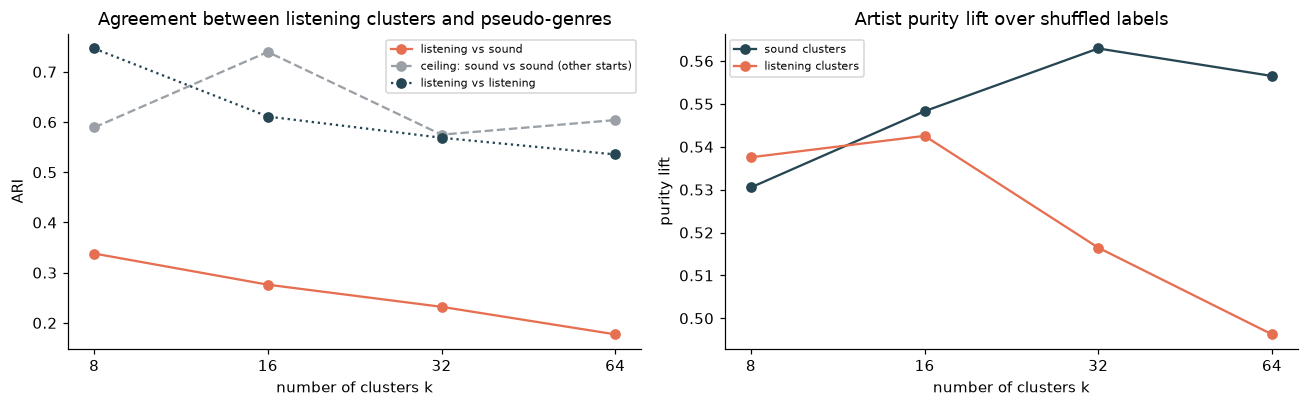

In [11]:
rows = []
listen_km = {(k, s): spherical_kmeans(Yu_o.astype(np.float32), k, SEED + 100 * s)[1] for k in K_GRID for s in range(N_SEEDS)}
for k in K_GRID:
    rows.append(dict(k=k, ari_listening_vs_sound=np.mean([adjusted_rand_score(listen_km[(k, s)], pgc[(k, s)]) for s in range(N_SEEDS)]),
                     nmi_listening_vs_sound=np.mean([normalized_mutual_info_score(listen_km[(k, s)], pgc[(k, s)]) for s in range(N_SEEDS)]),
                     ceiling_ari_sound_vs_sound=np.mean([adjusted_rand_score(pgc[(k, a)], pgc[(k, b)]) for a in range(N_SEEDS) for b in range(a + 1, N_SEEDS)]),
                     ceiling_nmi_sound_vs_sound=np.mean([normalized_mutual_info_score(pgc[(k, a)], pgc[(k, b)]) for a in range(N_SEEDS) for b in range(a + 1, N_SEEDS)]),
                     ari_listening_vs_listening=np.mean([adjusted_rand_score(listen_km[(k, a)], listen_km[(k, b)]) for a in range(N_SEEDS) for b in range(a + 1, N_SEEDS)]),
                     artist_lift_sound=purity_lift(pgc[(k, 0)]), artist_lift_listening=purity_lift(listen_km[(k, 0)])))
agree = pd.DataFrame(rows).set_index("k"); print(agree.T.to_string(float_format=lambda x: f"{x:.3f}"))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(agree.index, agree["ari_listening_vs_sound"], "o-", color=ACC, label="listening vs sound"); ax[0].plot(agree.index, agree["ceiling_ari_sound_vs_sound"], "o--", color=NULL, label="ceiling: sound vs sound (other starts)")
ax[0].plot(agree.index, agree["ari_listening_vs_listening"], "o:", color=REAL, label="listening vs listening")
ax[0].set(title="Agreement between listening clusters and pseudo-genres", xlabel="number of clusters k", ylabel="ARI")
ax[1].plot(agree.index, agree["artist_lift_sound"], "o-", color=REAL, label="sound clusters"); ax[1].plot(agree.index, agree["artist_lift_listening"], "o-", color=ACC, label="listening clusters")
ax[1].set(title="Artist purity lift over shuffled labels", xlabel="number of clusters k", ylabel="purity lift")
for a_ in ax: a_.set_xscale("log"); a_.set_xticks(K_GRID); a_.set_xticklabels(K_GRID); a_.minorticks_off(); a_.legend(fontsize=7)
plt.tight_layout(); plt.show()

### 5.3 Reading the pseudo-genres in listening space

**Every pseudo-genre is cohesive in listening space, at every k.** Tracks of the same pseudo-genre have more similar listening vectors than random pairs of tracks: the size-weighted lift is **0.19, 0.25, 0.29 and 0.32** for k = 8, 16, 32, 64, against about 0.000 with shuffled labels. At k = 32 **all 32 pseudo-genres have a positive lift** (lowest 0.17, median 0.31, highest 0.57).
No pseudo-genre is a purely acoustic category that listening ignores, and the lift grows with k because finer pseudo-genres are tighter. This is behavioural support for the pseudo-genres being real structure, from a source (listening sessions) that never saw the audio.

**About the exclusion of same-artist and same-album pairs.** The lift is the same with and without the exclusion (0.287, 0.285 and 0.287 at k = 32). This is not because the control is strong but because **such pairs are rare among random pairs of tracks within a pseudo-genre**: an artist's tracks are a tiny fraction of a pseudo-genre's tracks.
So this check, taken alone, is weak. The strong controls are the **unseen-artist split** in section 3 (the relation to sound is unchanged when no artist is shared between fitting and held-out tracks) and the edge-level control in the companion analysis of the co-listening graph, which removes same-artist and same-album edges directly.

**But grouping by listening gives a different partition from grouping by sound.** Clustering the listening embedding with the same k-means and comparing with the sound pseudo-genres gives an ARI of 0.34, 0.28, 0.23 and 0.18 and an NMI of 0.43, 0.44, 0.46 and 0.47 for k = 8, 16, 32, 64.
Two runs of the *sound* clustering agree at an ARI of 0.59, 0.74, 0.58 and 0.60 (NMI 0.66 to 0.78), and two runs of the listening clustering at 0.75, 0.61, 0.57 and 0.54, so the gap is far larger than random-start noise: sound and listening overlap well above chance (NMI about 0.45) but organise the tracks differently, and the disagreement in ARI grows with k.
The artist purity lift is similar for sound clusters (0.53 to 0.56) and listening clusters (0.50 to 0.54): both follow artists strongly.

**Together with sections 3 and 4:** sound explains a large part of listening (R² 0.44, also for unseen artists), the main shared axes are the pseudo-genre differences, every pseudo-genre is visible in listening at every k, and yet the two sources do not give the same clusters.
Part of the listening structure follows other things (mood, language, era and context are candidates, none tested here).

## 6. Extension: organic versus recommended listening

**Why.** The project's main question is whether recommended listening differs from organic listening. The sound-listening relation is one way to look at that: if recommended sessions follow sound *more* (or less) than organic sessions do, that is information about what the recommender does.
We trained the listening embedding on the recommended stream as well (same number of training tokens, same tracks, same settings) and repeat the key measurements, including the stricter checks: held-out artists, the k sweep, and the exclusion of same-artist and same-album pairs.

**How to read it.** Both embeddings are trained identically, so a difference reflects how listening was *generated* in each stream. Two cautions: sessions in the recommended stream are sequences chosen by the recommender (they may follow its own logic, possibly including audio similarity), and a difference does not say which stream is "better".

stream                                          organic  recommended
measure                                                             
R^2 audio -> listening (random tracks)            0.441        0.636
R^2 audio -> listening (unseen artists)           0.437        0.642
mean of top 10 canonical corr (random tracks)     0.782        0.845
mean of top 10 canonical corr (unseen artists)    0.784        0.848

cohesion lift, same-artist/album pairs excluded:
stream  organic  recommended
k                           
8         0.193        0.293
16        0.245        0.365
32        0.285        0.425
64        0.320        0.473

listening clusters vs sound pseudo-genres (ARI):
stream  organic  recommended
k                           
8         0.338        0.334
16        0.276        0.340
32        0.232        0.273
64        0.177        0.225

artist purity lift of listening clusters:
stream  organic  recommended
k                           
8         0.535        0.570
16      

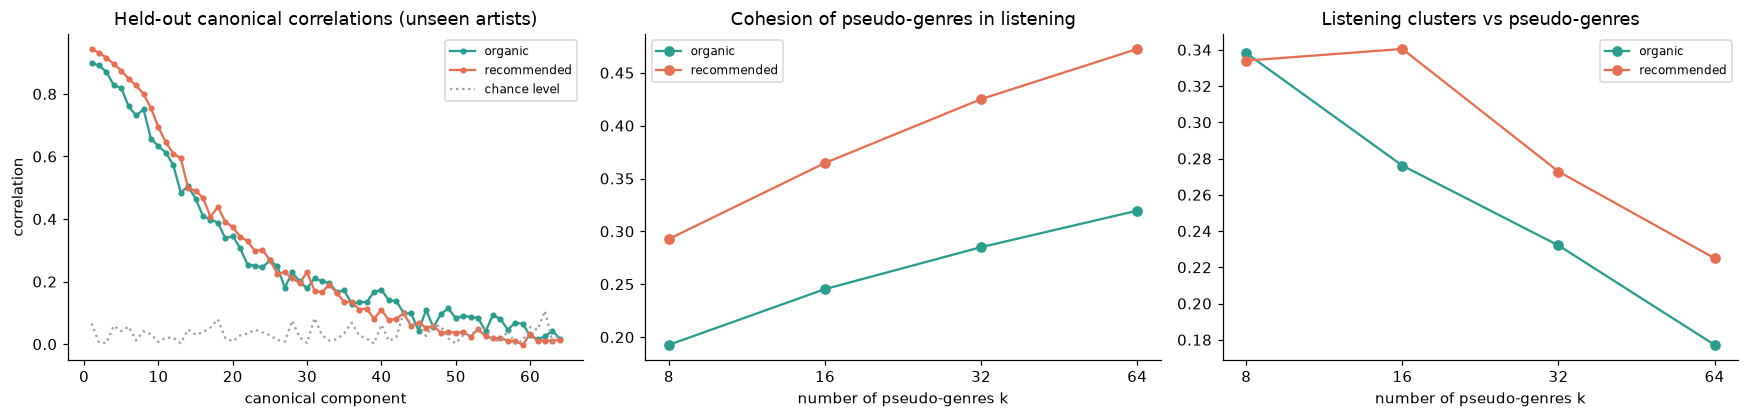

In [12]:
rows = []
Yu = {n: unit(Y[n]) for n in Y}
for n in ["organic", "recommended"]:
    for sp in splits:
        r_ = cca_res[(n, sp)]
        rows.append({"stream": n, "measure": f"R^2 audio -> listening ({sp})", "k": "", "value": r_["r2"]})
        rows.append({"stream": n, "measure": f"mean of top 10 canonical corr ({sp})", "k": "", "value": r_["rho_test"][:10].mean()})
    for k in K_GRID:
        lk = [spherical_kmeans(Yu[n].astype(np.float32), k, SEED + 100 * s)[1] for s in range(N_SEEDS)]
        rows.append({"stream": n, "measure": "cohesion lift, same-artist/album pairs excluded", "k": k, "value": np.mean([cohesion(Yu[n], pgc[(k, s)], k, "artist or album")[0] for s in range(N_SEEDS)])})
        rows.append({"stream": n, "measure": "listening clusters vs sound pseudo-genres (ARI)", "k": k, "value": np.mean([adjusted_rand_score(lk[s], pgc[(k, s)]) for s in range(N_SEEDS)])})
        rows.append({"stream": n, "measure": "artist purity lift of listening clusters", "k": k, "value": purity_lift(lk[0])})
st = pd.DataFrame(rows)
glob = st[st.k == ""].pivot(index="measure", columns="stream", values="value")[["organic", "recommended"]]
print(glob.to_string(float_format=lambda x: f"{x:.3f}"))
for meas in ["cohesion lift, same-artist/album pairs excluded", "listening clusters vs sound pseudo-genres (ARI)", "artist purity lift of listening clusters"]:
    print(f"\n{meas}:"); print(st[st.measure == meas].pivot(index="k", columns="stream", values="value")[["organic", "recommended"]].to_string(float_format=lambda x: f"{x:.3f}"))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.9))
for n in ["organic", "recommended"]:
    ax[0].plot(np.arange(1, 65), cca_res[(n, "unseen artists")]["rho_test"], "o-", ms=3, color=COL[n], label=n)
ax[0].plot(np.arange(1, 65), np.abs(cca_res[("organic", "unseen artists")]["rho_null"]), ":", color=NULL, label="chance level")
ax[0].set(title="Held-out canonical correlations (unseen artists)", xlabel="canonical component", ylabel="correlation"); ax[0].legend(fontsize=8)
for a_, meas, t in [(ax[1], "cohesion lift, same-artist/album pairs excluded", "Cohesion of pseudo-genres in listening"), (ax[2], "listening clusters vs sound pseudo-genres (ARI)", "Listening clusters vs pseudo-genres")]:
    for n in ["organic", "recommended"]:
        d = st[(st.measure == meas) & (st.stream == n)]; a_.plot(d["k"], d["value"], "o-", color=COL[n], label=n)
    a_.set(title=t, xlabel="number of pseudo-genres k"); a_.set_xscale("log"); a_.set_xticks(K_GRID); a_.set_xticklabels(K_GRID); a_.minorticks_off(); a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 6.1 Reading the comparison of streams

With equal training data (11.7 million tokens each), listening in the **recommended** stream is *more* aligned with sound than listening in the **organic** stream, on every measure, with unseen artists and for every k:

| Measure | Organic | Recommended |
|---|---|---|
| Held-out R² (audio to listening), random tracks / unseen artists | 0.44 / 0.44 | **0.64 / 0.64** |
| Mean of the top 10 canonical correlations (random / unseen artists) | 0.78 / 0.78 | **0.85 / 0.85** |
| Cohesion lift, k = 8 / 16 / 32 / 64 (same-artist and same-album pairs excluded) | 0.19 / 0.25 / 0.29 / 0.32 | **0.29 / 0.37 / 0.43 / 0.47** |
| Listening clusters vs sound pseudo-genres (ARI), k = 8 / 16 / 32 / 64 | 0.34 / 0.28 / 0.23 / 0.18 | 0.33 / **0.34 / 0.27 / 0.23** |
| Artist purity lift of listening clusters, k = 8 / 16 / 32 / 64 | 0.54 / 0.54 / 0.52 / 0.50 | **0.57 / 0.57 / 0.57 / 0.54** |

The differences in R² (0.64 against 0.44) and in cohesion lift (for example 0.43 against 0.29 at k = 32) are large compared with the run-to-run and seed variation seen elsewhere in this notebook (a few hundredths or less); the ARI at k = 8 is equal (0.34 organic against 0.33 recommended), and the ARI differences at larger k are smaller.

**A possible reading** is that the recommender chains tracks that sound alike, so what is played together in recommended sessions follows sound more than what users choose together. That would fit a recommender that uses audio or content similarity. **We did not test this**, and alternatives exist:
recommended sequences have a regularity of their own (longer sessions, 12.8 against 10.0 tracks, produced by an algorithm), organic sessions mix in many things that do not relate to sound (mood, context, replays of favourites), and the two streams are sessionised separately although the real listening of a user interleaves them.
The result is an *association between how a stream was generated and how well sound predicts it*; it does not show that the recommender narrows or broadens listening.

## 7. Evidence ledger, summary and limitations

Each row is one question about the pseudo-genres, which analysis answers it, what it found, and what it **does not** show. Numbers are for k = 32 unless stated. Sources: *k-means baseline* = notebook `RQ4_kmeans/RQ4_kmeans_k_selection`; *graph* = `01_pseudogenres_in_listening_graph`; *this notebook* = `02_sound_vs_listening`; *main question* = `03_genre_definitions_main_question`.

| Question | Analysis (source) | Result | What it does not show |
|---|---|---|---|
| **Is there structure beyond noise?** | k-means on real vs column-shuffled embeddings (k-means baseline §4) | silhouette 0.185 vs 0.008; mean cosine to centroid 0.68 vs 0.41 | that clusters are separate islands: absolute silhouette is weak (about 0.2) |
| **Do the clusters mean something outside sound?** (external label) | artist purity lift (k-means baseline §6) | 0.58 (75% of an artist's tracks in one cluster vs 17% with shuffled labels) | that clusters are genres: artists are a rough proxy |
| | held-out artists (this notebook §3) | R² of listening from sound 0.437 for unseen artists vs 0.441 for random tracks | nonlinear relations (linear methods) |
| **Are they visible in behaviour?** | modularity on a co-listening graph (graph §3) | Q = 0.48 vs 0.00 for shuffled labels; 54% of edge weight inside pseudo-genres vs 6% | how much of the listening structure they capture (no upper reference) |
| | same, without same-artist and same-album edges (graph §4) | Q = 0.33, i.e. 68% retained (61% to 76% for k = 64 to 8) | other shared attributes that are not recorded (label, era) |
| | cohesion in listening space (this notebook §5) | lift 0.29 vs 0.00; all 32 pseudo-genres positive (k = 8 to 64: 0.19 to 0.32) | (the same-artist pair exclusion is weak on its own, see §5.3) |
| **How much do sound and listening share?** | CCA and ridge (this notebook §3) | top canonical correlations 0.90, 0.89, 0.87; audio predicts 44% of listening variance; popularity regressed out: 43% | that they are the same structure |
| **Do they give the same clusters?** | listening clusters vs sound pseudo-genres (this notebook §5) | ARI 0.23, NMI 0.46 (ceiling for sound vs sound: ARI 0.58, NMI 0.74) | why they differ (mood, language, era and context are untested candidates) |
| **Is there a natural number of clusters?** | elbow, silhouette, artist lift (k-means baseline §2, 3, 6) | no elbow (about 18% inertia saved per doubling of k); silhouette plateau of about 0.20 from k = 48; artist lift peaks at k = 16 to 32 | |
| | modularity and cohesion across k (graph §3, this notebook §5) | Q falls with k (0.52 to 0.43) but the ratio to chance rises (4.3 to 14.5); cohesion lift rises with k (0.19 to 0.32) | |
| | **Reading:** no criterion has a sharp optimum; k = 32 lies within a plateau of roughly 16 to 64 and was kept as a convenient value | | that 32 is the "true" number of genres |
| **Are clusters reproducible?** | agreement between random starts (k-means baseline §5, graph §1) | ARI 0.58 to 0.69 (k-means baseline); 0.58 to 0.66 on all 848k tracks (graph) | single-cluster statements are fragile; aggregate statements are safer |
| **Does the answer to the main question depend on the definition of genre?** | recommended vs organic listening under 30 comparisons (main question) | 29 sound- or listening-based comparisons all show recommended listening **narrower** (P(recommended > organic) 0.25 to 0.39, intervals exclude 0.5); distinct artists show it **broader** (0.76) | the cause of the difference; effects are modest (about 1 pseudo-genre of 15) |

**What the sound-listening view adds to RQ4.**
1. **The pseudo-genres are visible in behaviour, at every k.** Tracks of the same pseudo-genre are listened to together more than chance (cohesion lift 0.19 to 0.32 for k = 8 to 64, against about 0 for shuffled labels; all 32 pseudo-genres positive at k = 32). They are not only an artefact of the clustering of audio.
2. **Sound and listening share a large, many-directional structure, and it is not about artists or popularity.** The strongest canonical correlations are about 0.90 on unseen tracks and on unseen artists alike, and audio alone predicts 44% of the variance of the listening embedding, also for artists never seen (R² 0.437); regressing popularity out changes it by 0.003.
3. **The strongest shared directions are mainly the differences between pseudo-genres** (for the first, 84% of the audio-side and 70% of the listening-side variance lies between them).
4. **But they are not the same structure.** Clustering the listening embedding gives a different partition (ARI 0.18 to 0.34, NMI 0.43 to 0.47, against 0.59 to 0.74 and 0.66 to 0.78 for sound against itself). The pseudo-genres should be read as a *sound-based* grouping that listening substantially, but not fully, follows.
5. **Extension:** with equal training data, recommended-stream listening is more aligned with sound than organic-stream listening (R² 0.64 against 0.44; cohesion lift 0.43 against 0.29 at k = 32). This is an association whose cause is untested.

**Limitations.**
- *Popular tracks only.* The 49,112 tracks are those with at least 20 plays in both streams; rarely played tracks (the long tail) are not described.
- *item2vec settings were fixed in advance, not tuned* (64 dimensions, window 5, 10 negative samples, 5 passes, frequent-track subsampling). Training with several threads is not bit-for-bit reproducible; a second seed gave the same headline numbers (section 3.4).
- *Linear methods.* CCA and ridge regression capture linear relations; nonlinear dependence would be missed, so the shared structure is a lower bound.
- *Controls cover recorded metadata only.* Unseen-artist testing and artist and album pair exclusion remove artist and album effects; they cannot remove other shared attributes that are not in the data (label, era, collaboration circles). The pair exclusion in section 5.1 is weak on its own (see there); the unseen-artist split is the strong control.
- *Pseudo-genres* are k-means clusters of the audio fitted on 150,000 tracks; two runs agree only at ARI 0.58 to 0.74, so single-cluster statements are fragile and aggregate statements are safer.
- *Stream comparison.* Streams were matched in training tokens, but not in the users, time periods or session length (12.8 against 10.0 tracks); sessions were formed within each stream separately although real listening interleaves them; recommended sequences are produced by a system.
- *Associations only*, in Yambda-50M (8,798 organic and 8,592 recommended-stream users).